In [1]:
from google.colab import drive

import numpy as np

import pandas as pd

import matplotlib as mpl
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F

In [11]:
drive.mount("/content/drive")

Mounted at /content/drive


In [12]:
cd /content/drive/MyDrive/colab_notebooks

/content/drive/MyDrive/colab_notebooks


In [ ]:
train_data, test_data = pd.read_csv("mnist_train.csv", header=None, index_col=False), pd.read_csv("mnist_test.csv", header=None, index_col=False)

In [ ]:
train_data.head()

,0,1,2,3,4,5,6,7,8,9,...,775,776,777,778,779,780,781,782,783,784
0,5,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,4,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,1,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [7]:
#hyperparameters
img_size = 32
batch_size = 16
nc = 8
nz = 32
lr = 2e-4
lr_coeff = 10
beta1 = 0.5
print_interval = 10

In [ ]:
train_data, test_data = torch.tensor(train_data), torch.tensor(test_data)
X_train, Y_train, X_test, Y_test = train_data[:, 1:], train_data[:, 0], test_data[:, 1:], test_data[:, 0]
X_train = X_train.view((X_train.shape[0], 28, 28)) / 255.0
X_train = torch.cat([torch.cat([X_train, torch.zeros(X_train.shape[0], 4, 28)], 1), torch.zeros(X_train.shape[0], 32, 4)], 2)
X_train = X_train.view(X_train.shape[0], 1, img_size, img_size)

<ipython-input-115-9bf89a564a4e>:1: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  train_data, test_data = torch.tensor(train_data), torch.tensor(test_data)


In [2]:
def get_batch(split):
  X_split = {"train": X_train, "test": X_test}[split]
  idx = torch.randint(0, X_split.shape[0], (batch_size,))
  X = X_split[idx]
  return X

In [3]:
class Discriminator(nn.Module):
  def __init__(self):
    super().__init__()
    self.layers = nn.ModuleList([nn.Conv2d(1, nc, 4, 2, 1), nn.BatchNorm2d(nc), nn.ReLU(),
                                 nn.Conv2d(nc, nc * 2, 4, 2, 1), nn.BatchNorm2d(nc * 2), nn.ReLU(),
                                 nn.Conv2d(nc * 2, nc * 4, 4, 2, 1), nn.BatchNorm2d(nc * 4), nn.ReLU(),
                                 nn.Conv2d(nc * 4, 1, 4, 1, 0), nn.Flatten(0, -1), nn.Sigmoid()])
  def forward(self, x):
    # (N, 1, img_size, img_size)
    for l in self.layers:
      x = l(x)
    return x # (N,)

class Generator(nn.Module):
  def __init__(self):
    super().__init__()
    self.layers = nn.ModuleList([nn.ConvTranspose2d(nz, nc * 4, 4, 1, 0), nn.BatchNorm2d(nc * 4), nn.ReLU(),
                                 nn.ConvTranspose2d(nc * 4, nc * 2, 4, 2, 1), nn.BatchNorm2d(nc * 2), nn.ReLU(),
                                 nn.ConvTranspose2d(nc * 2, nc, 4, 2, 1), nn.BatchNorm2d(nc), nn.ReLU(),
                                 nn.ConvTranspose2d(nc, 1, 4, 2, 1), nn.Sigmoid()])
  def forward(self, x):
    # (N, nz)
    N = x.shape[0]
    x = x.view(N, nz, 1, 1)
    for l in self.layers:
      x = l(x)
    return x # (N, 1, img_size, img_size)

In [4]:
loss_fn = nn.BCELoss()

In [5]:
def train(n_iter):
  G.train()
  D.train()
  losses_G, losses_D = [], []
  zeros, ones = torch.zeros(batch_size), torch.ones(batch_size)
  for i in range(1, n_iter + 1):
    optG.zero_grad()
    optD.zero_grad()

    X = get_batch("train")
    yd_real = D(X)
    noise = torch.randn(batch_size, nz)
    fake = G(noise)
    yd_fake1 = D(fake.detach())
    lossD_real = loss_fn(yd_real, ones)
    lossD_fake = loss_fn(yd_fake1, zeros)
    lossD = lossD_real + lossD_fake
    lossD.backward()
    optD.step()

    yd_fake2 = D(fake)
    lossG = loss_fn(yd_fake2, ones)
    lossG.backward()
    optG.step()

    losses_G.append(lossG.item())
    losses_D.append(lossD.item())
    if i % print_interval == 0:
      print("iter:", i, "lossD:", lossD.item(), "lossG:", lossG.item())
  return losses_G, losses_D

In [8]:
D = Discriminator()
G = Generator()

In [9]:
optD = torch.optim.AdamW(D.parameters(), lr=lr, betas=(beta1, 0.999))
optG = torch.optim.AdamW(G.parameters(), lr=lr * lr_coeff, betas=(beta1, 0.999))

In [ ]:
# torch.save(G.state_dict(), "gan_g.pth")
# torch.save(D.state_dict(), "gan_d.pth")

In [13]:
# G.load_state_dict(torch.load("gan_g.pth"))
# D.load_state_dict(torch.load("gan_d.pth"))

<All keys matched successfully>

In [ ]:
losses_G, losses_D = train(1000)

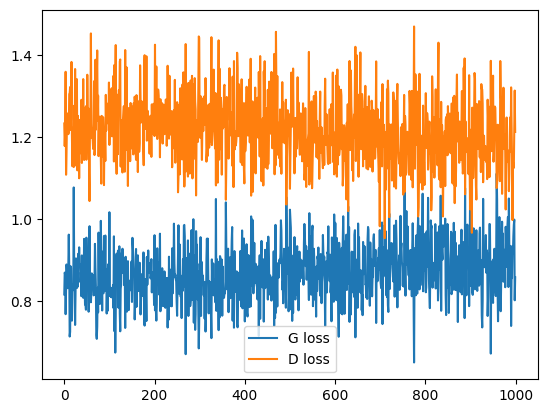

In [ ]:
plt.plot(losses_G, label="G loss")
plt.plot(losses_D, label="D loss")
plt.legend()

Generator(
  (layers): ModuleList(
    (0): ConvTranspose2d(32, 32, kernel_size=(4, 4), stride=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): ConvTranspose2d(32, 16, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): ConvTranspose2d(16, 8, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU()
    (9): ConvTranspose2d(8, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (10): Sigmoid()
  )
)

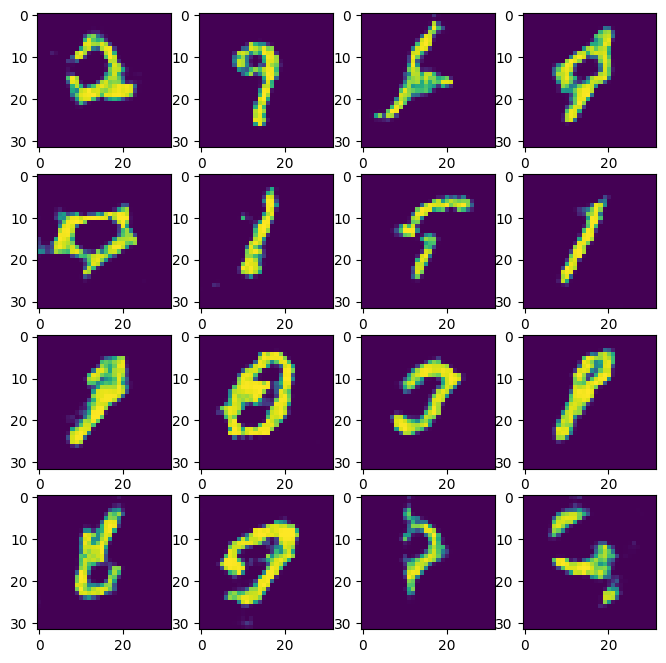

In [55]:
G.eval()
with torch.no_grad():
  noise = torch.randn(batch_size, nz)
  Y = G(noise).detach()
  fig, axs = plt.subplots(4, 4, figsize=(8, 8))
  for i in range(4):
    for j in range(4):
      axs[i][j].imshow(Y[i * 4 + j, 0])
G.train()

Generator(
  (layers): ModuleList(
    (0): ConvTranspose2d(32, 32, kernel_size=(4, 4), stride=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): ConvTranspose2d(32, 16, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (4): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): ConvTranspose2d(16, 8, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (7): BatchNorm2d(8, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU()
    (9): ConvTranspose2d(8, 1, kernel_size=(4, 4), stride=(2, 2), padding=(1, 1))
    (10): Sigmoid()
  )
)

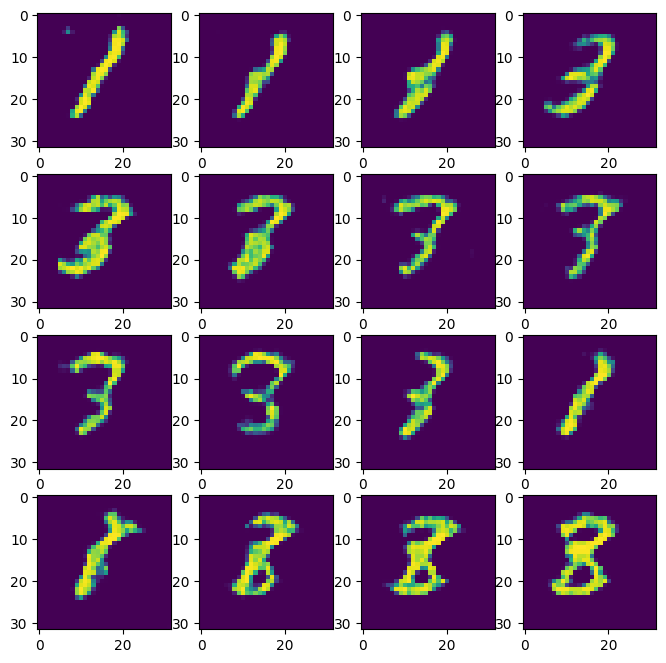

In [66]:
G.eval()
with torch.no_grad():
  noise = torch.randn(1, nz)
  # add_noise = torch.randn(1, nz) / 10.0
  fig, axs = plt.subplots(4, 4, figsize=(8, 8))
  for i in range(4):
    for j in range(4):
      Y = G(noise).detach()
      axs[i][j].imshow(Y[0, 0])
      noise += torch.randn(1, nz) / 2.0
      noise /= noise.std().item()
G.train()

In [14]:
X = get_batch("train")
fig, axs = plt.subplots(4, 4, figsize=(8, 8))
for i in range(4):
  for j in range(4):
    axs[i][j].imshow(X[i * 4 + j, 0])

NameError: name 'X_train' is not defined